## Brand sales per year (Video Game Sales)
This section loads the video game sales data if not already loaded, maps `Platform` to `Brand` (Nintendo, Sony, Microsoft, Sega, PC, Other), aggregates by year, and plots:
- Total global sales per brand by year
- Number of games per brand by year
It also prints a small summary table for the last 10 years in the data.


In [25]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load vgsales if not already loaded
if 'df' not in globals():
    PATH = 'data/vgsales.csv'
    if not os.path.exists(PATH):
        raise FileNotFoundError(f"Dataset not found at {PATH}")
    df = pd.read_csv(PATH)
    df = df.dropna(subset=['Year']).copy()
    df['Publisher'] = df['Publisher'].fillna('Unknown')
    df['Genre'] = df['Genre'].fillna('Unknown')




![green-divider](https://user-images.githubusercontent.com/7065401/52071924-c003ad80-2562-11e9-8297-1c6595f8a7ff.png)
# Hackathon Notebook
![green-divider](https://user-images.githubusercontent.com/7065401/52071924-c003ad80-2562-11e9-8297-1c6595f8a7ff.png)


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [27]:
file_path = "data/vgsales.csv"
video_games_df = pd.read_csv(file_path)
video_games_df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


# Discover the Data

In [28]:
# Display dataset overview with neat formatting
print("="*40)
print("First 5 Rows of the Dataset")
print("="*40)
print(video_games_df.head().to_string(index=False))

print("\n" + "="*40)
print("Column Names")
print("="*40)
print(video_games_df.columns.tolist())

print("\n" + "="*40)
print("Last 5 Rows of the Dataset")
print("="*40)
print(video_games_df.tail().to_string(index=False))

print("\n" + "="*40)
print("Dataset Info")
print("="*40)
video_games_df.info()

print("\n" + "="*40)
print("Dataset Shape (rows, columns)")
print("="*40)
print(video_games_df.shape)

print("\n" + "="*40)
print("Missing Values per Column")
print("="*40)
print(video_games_df.isnull().sum())

# Check for duplicate rows
duplicate_count = video_games_df.duplicated(keep='first').sum()
print("\n" + "="*40)
print(f"Number of duplicate rows: {duplicate_count}")
print("="*40)

if duplicate_count > 0:
    print("\nDuplicate Rows:")
    print(video_games_df[video_games_df.duplicated(keep=False)].to_string(index=False))
else:
    print("No duplicate rows found")


First 5 Rows of the Dataset
 Rank                     Name Platform   Year        Genre Publisher  NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
    1               Wii Sports      Wii 2006.0       Sports  Nintendo     41.49     29.02      3.77         8.46         82.74
    2        Super Mario Bros.      NES 1985.0     Platform  Nintendo     29.08      3.58      6.81         0.77         40.24
    3           Mario Kart Wii      Wii 2008.0       Racing  Nintendo     15.85     12.88      3.79         3.31         35.82
    4        Wii Sports Resort      Wii 2009.0       Sports  Nintendo     15.75     11.01      3.28         2.96         33.00
    5 Pokemon Red/Pokemon Blue       GB 1996.0 Role-Playing  Nintendo     11.27      8.89     10.22         1.00         31.37

Column Names
['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']

Last 5 Rows of the Dataset
 Rank                                     

# Data Cleaning

In [29]:
# Checking for duplicates (to reduce variability)
print(f"Initial records: {len(video_games_df)}")
video_games_df = video_games_df.drop_duplicates()
print(f"After deduplication: {len(video_games_df)}")

#Dropping Null Columns (the nulls in our data are only in the year and publisher columns and they account for almost 2% of the columns, and in this case we can drop them)
df_clean = video_games_df.dropna(subset=['Year', 'Publisher'])

# Summary Printing
print("Original Shape:", video_games_df.shape)
print("New Shape:", df_clean.shape)
print("Rows Dropped:", video_games_df.shape[0] - df_clean.shape[0])
print("Percentage Dropped:", round(((video_games_df.shape[0] - df_clean.shape[0]) / video_games_df.shape[0]) * 100, 2), "%")

#Changing the Year column data type to int
df_clean['Year'] = df_clean['Year'].astype(int)



Initial records: 16598
After deduplication: 16598
Original Shape: (16598, 11)
New Shape: (16291, 11)
Rows Dropped: 307
Percentage Dropped: 1.85 %


# Approach 1

In [30]:
RANDOM_STATE = 42
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold

np.random.seed(RANDOM_STATE)
# Features/target (original columns only)
features = ['NA_Sales','EU_Sales','JP_Sales','Other_Sales','Platform','Genre','Publisher','Year']
target = 'Global_Sales'
X = df[features].copy()
y = df[target].copy()

print('Data:', X.shape, 'Target:', y.shape)

# Split & preprocess
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

numeric_cols = ['NA_Sales','EU_Sales','JP_Sales','Other_Sales','Year']
cat_cols = ['Platform','Genre','Publisher']
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


Data: (16327, 8) Target: (16327,)


# Approach 2
- Here we will be dropping the Rank and Name columns and that is because Rank is actually just ranking global sales and would be redundant in analysis
- As for the name column, it’s mostly an ID, not a causal driver of sales. If kept, models can memorize specific names from training and look unrealistically accurate—classic overfitting behavior

- Here, to use the LinearRegression Model,  we will drop all sale columns other than the Global Sales because adding them all up results in the Global Sales

In [31]:

df_reg = df_clean.drop(columns = ['Rank','Name','NA_Sales','EU_Sales','JP_Sales','Other_Sales'])
df_reg

,Platform,Year,Genre,Publisher,Global_Sales
0,Wii,2006,Sports,Nintendo,82.74
1,NES,1985,Platform,Nintendo,40.24
2,Wii,2008,Racing,Nintendo,35.82
3,Wii,2009,Sports,Nintendo,33.00
4,GB,1996,Role-Playing,Nintendo,31.37
...,...,...,...,...,...
16593,GBA,2002,Platform,Kemco,0.01
16594,GC,2003,Shooter,Infogrames,0.01
16595,PS2,2008,Racing,Activision,0.01
16596,DS,2010,Puzzle,7G//AMES,0.01


# Visualizations

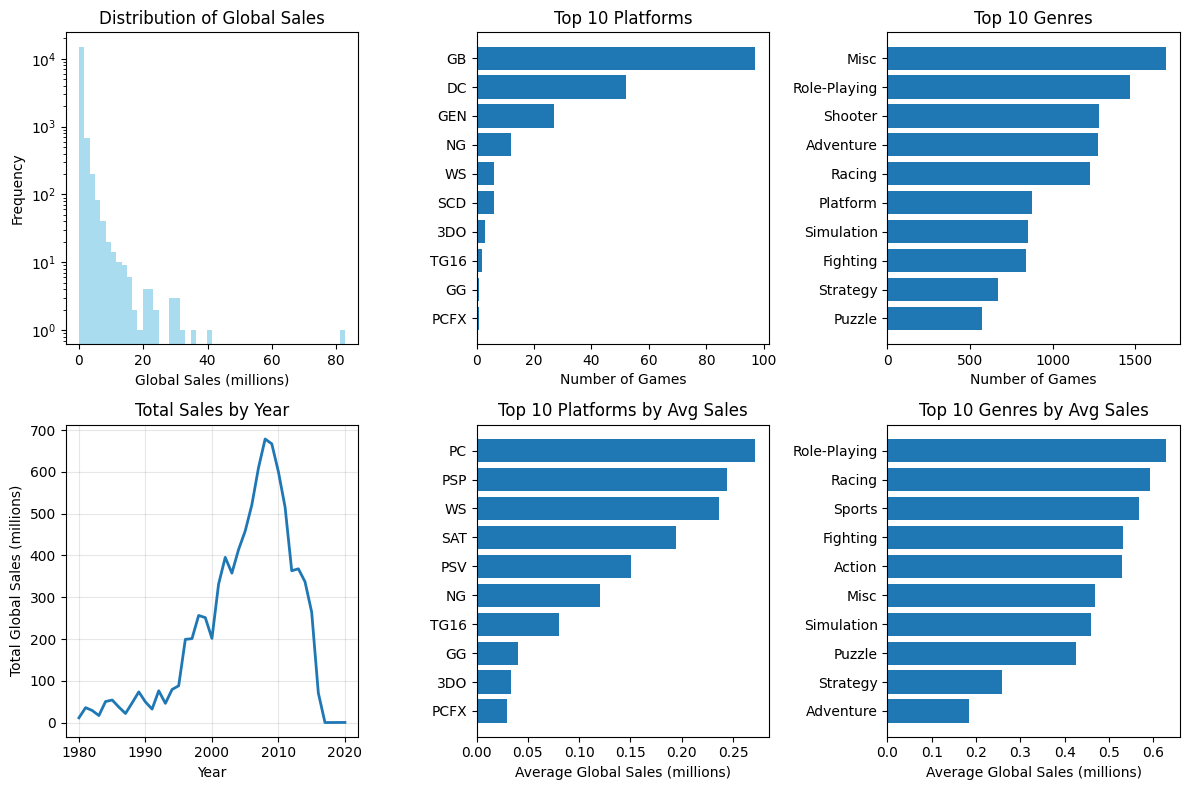

Total games: 16,291
Year range: 1980 - 2020
Average global sales: 0.54 million units
Top platform: DS
Top genre: Action
Best selling platform (avg): GB
Best selling genre (avg): Platform


In [32]:
# Let's look at the distribution of global sales
plt.figure(figsize=(12, 8))
 
# 1. Global Sales Distribution
plt.subplot(2, 3, 1)
plt.hist(df_reg['Global_Sales'], bins=50, alpha=0.7, color='skyblue')
plt.xlabel('Global Sales (millions)')
plt.ylabel('Frequency')
plt.title('Distribution of Global Sales')
plt.yscale('log') # we used log scale for the visual to look clearer and more insightful
 
 
# 2. Top Platforms
plt.subplot(2, 3, 2)
top_platforms = df_reg['Platform'].value_counts().sort_values(ascending = True).head(10)
plt.barh(range(len(top_platforms)), top_platforms.values)
plt.yticks(range(len(top_platforms)), top_platforms.index)
plt.xlabel('Number of Games')
plt.title('Top 10 Platforms')
 
# 3. Top Genres
plt.subplot(2, 3, 3)
top_genres = df_reg['Genre'].value_counts().sort_values(ascending = True).head(10)
plt.barh(range(len(top_genres)), top_genres.values)
plt.yticks(range(len(top_genres)), top_genres.index)
plt.xlabel('Number of Games')
plt.title('Top 10 Genres')
 
# 4. Sales by Year
plt.subplot(2, 3, 4)
yearly_sales = df_reg.groupby('Year')['Global_Sales'].sum()
plt.plot(yearly_sales.index, yearly_sales.values, linewidth=2)
plt.xlabel('Year')
plt.ylabel('Total Global Sales (millions)')
plt.title('Total Sales by Year')
plt.grid(True, alpha=0.3)
 
# 5. Average Sales by Platform
plt.subplot(2, 3, 5)
platform_avg = df_reg.groupby('Platform')['Global_Sales'].mean().sort_values(ascending=True).head(10)
plt.barh(range(len(platform_avg)), platform_avg.values)
plt.yticks(range(len(platform_avg)), platform_avg.index)
plt.xlabel('Average Global Sales (millions)')
plt.title('Top 10 Platforms by Avg Sales')
 
# 6. Average Sales by Genre
plt.subplot(2, 3, 6)
genre_avg = df_reg.groupby('Genre')['Global_Sales'].mean().sort_values(ascending= True).head(10)
plt.barh(range(len(genre_avg)), genre_avg.values)
plt.yticks(range(len(genre_avg)), genre_avg.index)
plt.xlabel('Average Global Sales (millions)')
plt.title('Top 10 Genres by Avg Sales')
 
plt.tight_layout()
plt.show()
 
# insigts from the charts
print(f"Total games: {len(df_reg):,}")
print(f"Year range: {df_reg['Year'].min()} - {df_reg['Year'].max()}")
print(f"Average global sales: {df_reg['Global_Sales'].mean():.2f} million units")
print(f"Top platform: {df_reg['Platform'].value_counts().index[0]}")
print(f"Top genre: {df_reg['Genre'].value_counts().index[0]}")
print(f"Best selling platform (avg): {df_reg.groupby('Platform')['Global_Sales'].mean().idxmax()}")
print(f"Best selling genre (avg): {df_reg.groupby('Genre')['Global_Sales'].mean().idxmax()}")
 


In [44]:
feature_columns = ["Platform", "Year", "Genre", "Publisher"]
target_column   = "Global_Sales"

data = df_reg[feature_columns + [target_column]].copy()
data[target_column] = pd.to_numeric(data[target_column], errors="coerce").fillna(0).clip(lower=0)

# 2) Split into train/test 
X_features = data[feature_columns]
y_target   = data[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_target, test_size=0.20, random_state=42
)

# 3) Preprocess categorical columns
categorical_columns = ["Platform", "Genre", "Publisher"]
numeric_columns     = ["Year"]

preprocessor = ColumnTransformer(
    transformers=[
        ("onehot", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("pass_year", "passthrough", numeric_columns),
    ]
)


regressor = RandomForestRegressor(
    n_estimators=300,   # number of trees (simple, works well)
    random_state=42,
    n_jobs=-1
)

# 5) Build the pipeline (preprocess -> model)
model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("regressor", regressor)
])

# 6) Model Training
model.fit(X_train, y_train)

# 7) Predict & evaluate 
y_pred = model.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred)  # RMSE = sqrt(MSE)
r2   = r2_score(y_test, y_pred)

print("---- Regression Results (Global_Sales) ----")
print(f"MAE : {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R^2 : {r2:.4f}")

# quick business view: hits vs non-hits 
# Define success as >= 1.0M units; change if you want.
success_threshold = 1.0
actual_is_hit    = (y_test >= success_threshold).astype(int)
pred_is_hit      = (y_pred >= success_threshold).astype(int)


# Peek at a few rows
preview = pd.DataFrame({
    "Year": X_test["Year"],
    "Global_Sales_True": y_test,
    "Global_Sales_Pred": y_pred
}).head(10)
print("\nSample predictions:")
print(preview.to_string(index=False))

---- Regression Results (Global_Sales) ----
MAE : 0.5191
RMSE: 4.1403
R^2 : 0.0322

Sample predictions:
 Year  Global_Sales_True  Global_Sales_Pred
 2008               0.57           0.495409
 2014               0.07           0.034516
 2015               0.19           0.107138
 2011               0.67           0.033884
 2001               0.22           0.203834
 2007               0.11           0.269583
 2016               0.17           0.222565
 2010               0.13           0.159178
 2006               0.02           0.052189
 2010               0.21           0.170970


In [34]:
df_clean.to_csv("data/vgsales_clean.csv")

# Reasoning for a low score

We wanted to know why there was such a low r-squared score. So to dhtat we explore different plots

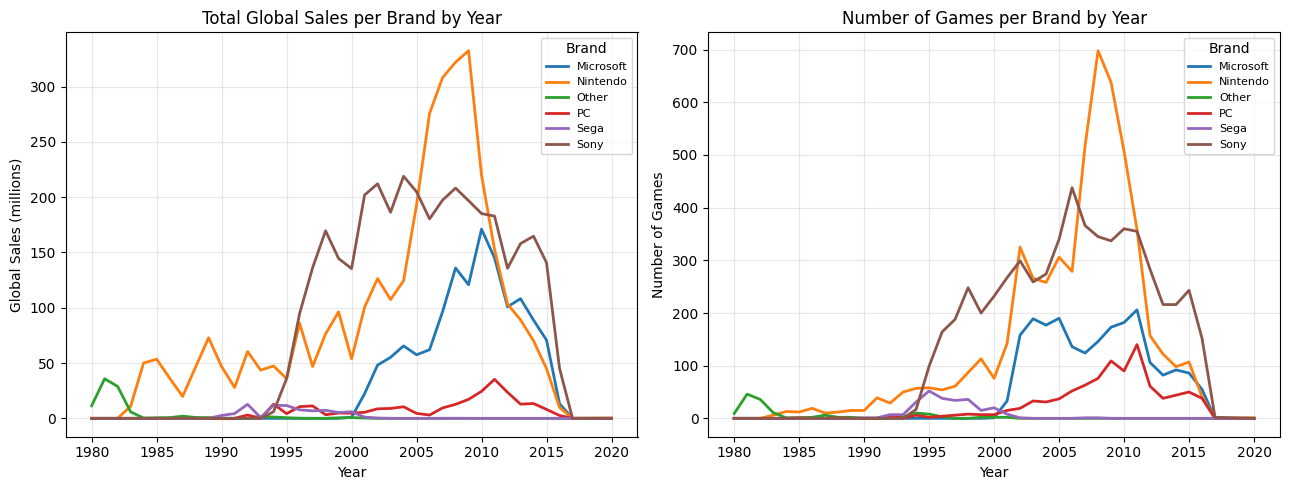

=== YEARLY BRAND SUMMARY (last 10 years in data) ===
Brand   Microsoft  Nintendo  Other     PC  Sega    Sony
Year                                                   
2009.0     120.85    332.43    0.0  17.16   0.0  196.86
2010.0     171.05    219.78    0.0  24.46   0.0  185.16
2011.0     145.12    152.74    0.0  35.25   0.0  182.88
2012.0     100.88    103.39    0.0  23.53   0.0  135.74
2013.0     108.21     89.04    0.0  12.83   0.0  158.03
2014.0      88.85     70.11    0.0  13.39   0.0  164.70
2015.0      70.71     44.92    0.0   8.07   0.0  140.74
2016.0      13.20      9.89    0.0   2.60   0.0   45.24
2017.0       0.00      0.00    0.0   0.00   0.0    0.05
2020.0       0.00      0.29    0.0   0.00   0.0    0.00


In [43]:
# Map platforms to brands
brand_map = {
    'Wii': 'Nintendo','WiiU': 'Nintendo','NES': 'Nintendo','SNES': 'Nintendo','N64': 'Nintendo','GC': 'Nintendo',
    '3DS': 'Nintendo','DS': 'Nintendo','GB': 'Nintendo','GBA': 'Nintendo','Switch': 'Nintendo','NS': 'Nintendo',
    'PS': 'Sony','PS2': 'Sony','PS3': 'Sony','PS4': 'Sony','PS5': 'Sony','PSP': 'Sony','PSV': 'Sony',
    'XB': 'Microsoft','X360': 'Microsoft','XOne': 'Microsoft','XSX': 'Microsoft',
    'GEN': 'Sega','SAT': 'Sega','DC': 'Sega','GG': 'Sega',
    'PC': 'PC',
    '2600': 'Other','TG16': 'Other','3DO': 'Other','NG': 'Other','WS': 'Other'
}

dfb = df.copy()
dfb['Brand'] = dfb['Platform'].map(brand_map).fillna('Other')

# Ensure Year numeric
dfb['Year'] = pd.to_numeric(dfb['Year'], errors='coerce')

yearly_brand_sales = dfb.groupby(['Year','Brand'])['Global_Sales'].sum().unstack(fill_value=0).sort_index()
yearly_brand_counts = dfb.groupby(['Year','Brand'])['Name'].nunique().unstack(fill_value=0).sort_index()

plt.figure(figsize=(13, 5))

# Sales per brand over time
plt.subplot(1, 2, 1)
for brand in yearly_brand_sales.columns:
    plt.plot(yearly_brand_sales.index, yearly_brand_sales[brand], label=brand, linewidth=2)
plt.title('Total Global Sales per Brand by Year')
plt.xlabel('Year')
plt.ylabel('Global Sales (millions)')
plt.grid(True, alpha=0.3)
plt.legend(title='Brand', fontsize=8)

# Number of games per brand per year
plt.subplot(1, 2, 2)
for brand in yearly_brand_counts.columns:
    plt.plot(yearly_brand_counts.index, yearly_brand_counts[brand], label=brand, linewidth=2)
plt.title('Number of Games per Brand by Year')
plt.xlabel('Year')
plt.ylabel('Number of Games')
plt.grid(True, alpha=0.3)
plt.legend(title='Brand', fontsize=8)

plt.tight_layout()
plt.show()

print("=== YEARLY BRAND SUMMARY (last 10 years in data) ===")
print(yearly_brand_sales.tail(10).round(2).to_string())

We concluded that the reason the r-squared was due to noisy data. Game brand such as nintendo used to mass export games causing most games to reach a low score. Due to that, trying to predict without using any of the regional sales has shown to be ineffective as most likely the model will undershoot.

# Now lets try it with regional pricing

We used two different models here, a regression line and a random forest regression model.

# Regression line

For the regression line, we went with an approach that as we know that regional pricing is correlated with global sales, we want to investiagte which region has the most effect on it. To do this, we created a simple regression line over the four regions and showcased the findings.

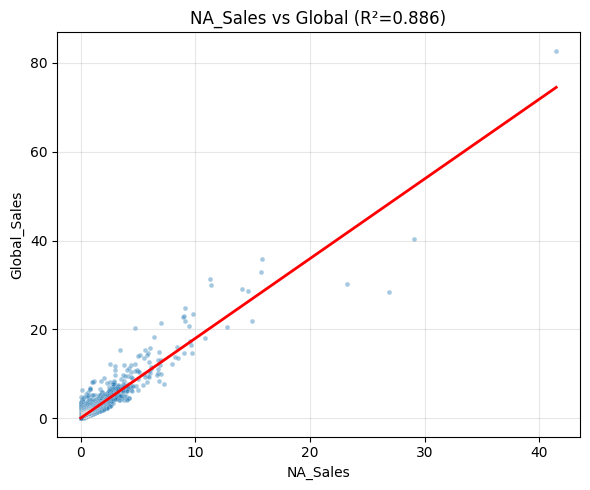

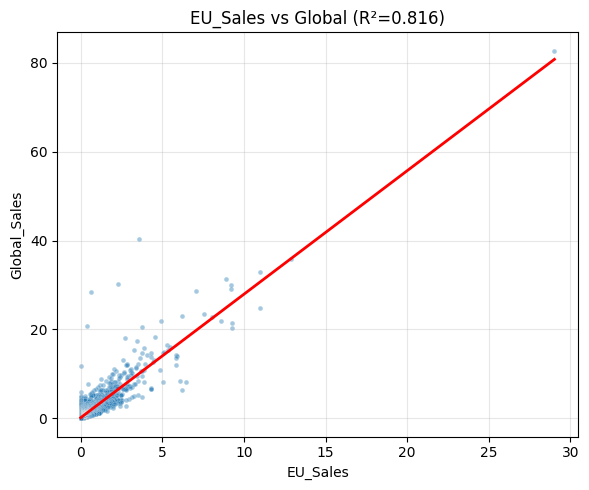

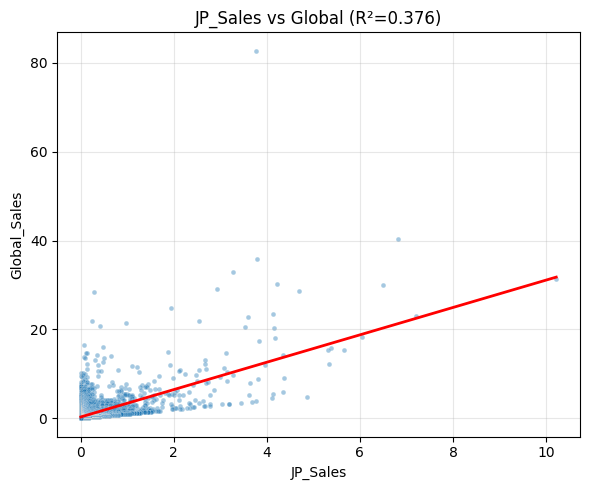

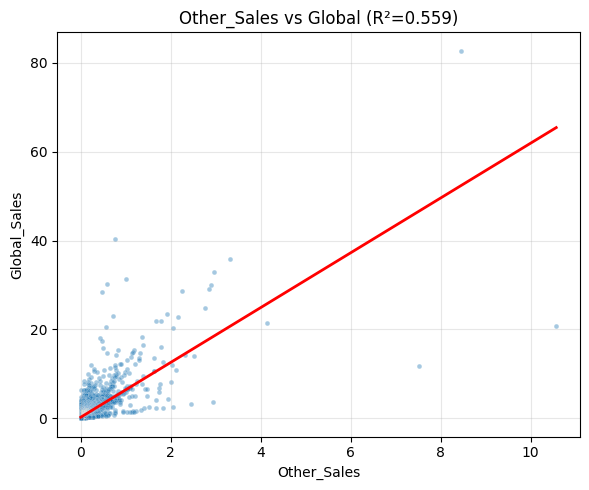

Regional single-feature regressions against Global_Sales:
     Region    Slope  Intercept       R2
   NA_Sales 1.793804   0.064129 0.885985
   EU_Sales 2.779826   0.130056 0.815898
Other_Sales 6.167546   0.242182 0.559465
   JP_Sales 3.079600   0.297987 0.375516


In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Regions to analyze
regions = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']

summary = []

# Create a separate plot for each region
for reg in regions:
    Xr = df[[reg]].values
    yr = df['Global_Sales'].values
    lr = LinearRegression().fit(Xr, yr)
    yhat = lr.predict(Xr)
    r2 = r2_score(yr, yhat)
    slope = lr.coef_[0]
    intercept = lr.intercept_
    summary.append({'Region': reg, 'Slope': slope, 'Intercept': intercept, 'R2': r2})

    plt.figure(figsize=(6, 5))
    sns.scatterplot(x=df[reg], y=df['Global_Sales'], alpha=0.4, s=12)
    x_line = np.linspace(df[reg].min(), df[reg].max(), 200).reshape(-1, 1)
    plt.plot(x_line, lr.predict(x_line), color='red', linewidth=2)
    plt.title(f'{reg} vs Global (R²={r2:.3f})')
    plt.xlabel(reg)
    plt.ylabel('Global_Sales')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Summary table
summary_df = pd.DataFrame(summary).sort_values('R2', ascending=False)
print('Regional single-feature regressions against Global_Sales:')
print(summary_df.to_string(index=False))


In [77]:
# Cross-validation for LinearRegression (per region and combined) with R², MAE, MSE
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import make_scorer, r2_score, mean_absolute_error, mean_squared_error

regions = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'r2': 'r2',
    'mae': 'neg_mean_absolute_error',
    'mse': 'neg_mean_squared_error'
}

print("Single-feature LinearRegression cross-validation:")
for reg in regions:
    Xr = df[[reg]].values
    yr = df['Global_Sales'].values
    model = LinearRegression()
    scores = cross_validate(model, Xr, yr, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=False)
    r2_mean = scores['test_r2'].mean();   r2_std = scores['test_r2'].std()
    mae_mean = -scores['test_mae'].mean(); mae_std = scores['test_mae'].std()
    mse_mean = -scores['test_mse'].mean(); mse_std = scores['test_mse'].std()
    print(f"  {reg:12s}  R²={r2_mean:.4f} MAE={mae_mean:.4f} MSE={mse_mean:.4f}")

# Combined regional model (all four regions together)
X_all = df[regions].values
y_all = df['Global_Sales'].values
combined = cross_validate(LinearRegression(), X_all, y_all, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=False)


Single-feature LinearRegression cross-validation:
  NA_Sales      R²=0.8710 MAE=0.2016 MSE=0.3015
  EU_Sales      R²=0.8054 MAE=0.2460 MSE=0.4516
  JP_Sales      R²=0.3736 MAE=0.5050 MSE=1.5441
  Other_Sales   R²=0.4844 MAE=0.3254 MSE=1.1474


As shown above, the R2 score for the NA Sales is around 88% which is very high. Now that we know that, we decided to stick with NA region as our main predictor as it has the highest r2 score. While we used cross validation to ensure there is no overfitting in our model.

The reason for that is because NA sales has the highest amount of sales in almost every row.

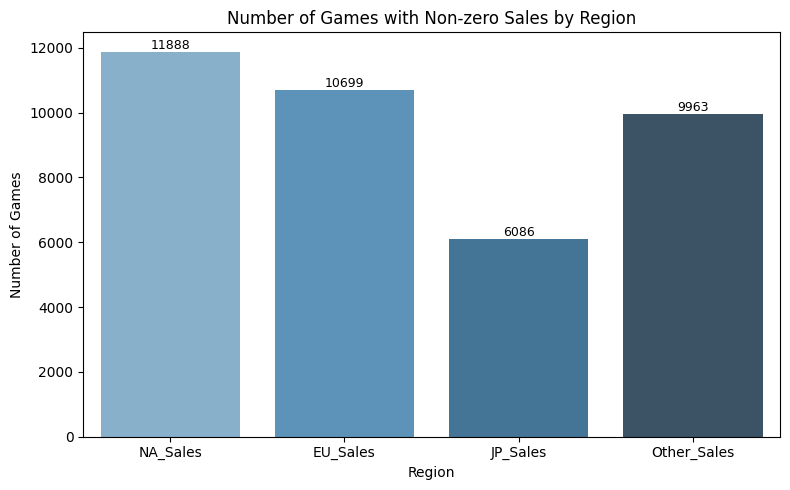

In [38]:
# Count of games sold per region (non-zero sales)
import matplotlib.pyplot as plt
import seaborn as sns

regions = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']

counts = []
for reg in regions:
    counts.append((reg, int((df[reg] > 0).sum())))

labels = [r for r, _ in counts]
values = [c for _, c in counts]

plt.figure(figsize=(8, 5))
sns.barplot(x=labels, y=values, palette='Blues_d')
plt.title('Number of Games with Non-zero Sales by Region')
plt.xlabel('Region')
plt.ylabel('Number of Games')
for i, v in enumerate(values):
    plt.text(i, v, str(v), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()


# Random tree approach

For our second apporach, we decided to go with random tree regression.

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries ready")

Libraries ready


In [40]:
# Load data
PATH = 'data/vgsales.csv'
df = pd.read_csv(PATH)

# We dropped all rows where year is empty and filled publisher and Genre with Unkown
df = df.dropna(subset=['Year']).copy()
df['Publisher'] = df['Publisher'].fillna('Unknown')
df['Genre'] = df['Genre'].fillna('Unknown')

# We chose our features and targets
features = ['NA_Sales','EU_Sales','JP_Sales','Other_Sales','Platform','Genre','Publisher','Year']
target = 'Global_Sales'
X = df[features].copy()
y = df[target].copy()


print('Data:', X.shape, 'Target:', y.shape)


Data: (16327, 8) Target: (16327,)


We used both standard scaler for numerical columns to scale them and ensure that output doesn't get bias;d by the difference of margins. 

We also used OneHotEncoder to ensure that categroical columns are now usable.

And using K fold, we trained the model to ensure that the training and testing and columns change, so we can ensure that the model is trained without bias.

In [41]:
# Splitting the data and setting up the preprocessor
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

numeric_cols = ['NA_Sales','EU_Sales','JP_Sales','Other_Sales','Year']
cat_cols = ['Platform','Genre','Publisher']
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])
# The Kfold
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


In [ ]:
# Training the data 
y_train_t = np.log1p(y_train) 
y_test_t = np.log1p(y_test) 
# Creating a pipeline for the preprocessor and model
rf = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))
])
rf.fit(X_train, y_train_t)

# Evaluation
def inv(z):
    return np.expm1(z) 

p_train = inv(rf.predict(X_train))
p_test = inv(rf.predict(X_test))

print("RandomForest Results:")
print(f"  Train R²: {r2_score(y_train, p_train):.4f}")
print(f"  Test  R²: {r2_score(y_test, p_test):.4f}")
print(f"  Test  MSE: {mean_squared_error(y_test, p_test):.4f}")
print(f"  Test  MAE: {mean_absolute_error(y_test, p_test):.4f}")




RandomForest Results:
  Train R²: 0.9921
  Test  R²: 0.8109
  Test  MSE: 0.8081
  Test  MAE: 0.0452
